# Qiskit Fall Fest 2026 – Challenge 3: Can You Change the Correlation?

**Goal:** Start from the Bell-state circuit, add **one** gate, and see how the relationship between the two measured bits changes (100 shots each).

**Original (Bell) circuit:** `H` on qubit 0, then `CX` (control q0, target q1):

$$|00\rangle \xrightarrow{H\otimes I} \tfrac{1}{\sqrt2}(|00\rangle+|10\rangle) \xrightarrow{CX} \tfrac{1}{\sqrt2}(|00\rangle+|11\rangle)=|\Phi^+\rangle$$

Both qubits always agree, so only `00` and `11` appear.

**Modification:** add an `X` gate on qubit 1 right after the CX.

> Qiskit prints bitstrings as `q1 q0` (qubit 0 is the rightmost bit).

In [1]:
# !pip install qiskit qiskit-aer matplotlib pylatexenc   # uncomment if needed
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

SHOTS = 100
sim = AerSimulator()

def run(qc, shots=SHOTS):
    return sim.run(qc, shots=shots).result().get_counts()

def correlated_fraction(counts):
    same = counts.get('00', 0) + counts.get('11', 0)
    return same / sum(counts.values())

## 1. Original circuit – Bell state

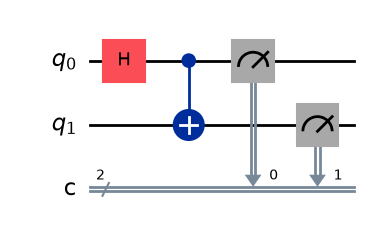

In [2]:
qc_bell = QuantumCircuit(2, 2)
qc_bell.h(0)
qc_bell.cx(0, 1)
qc_bell.measure([0, 1], [0, 1])
display(qc_bell.draw(output='mpl'))   # use print(qc_bell.draw()) if mpl is unavailable

## 2. Modified circuit – add one `X` gate on qubit 1

### Prediction (before running)
- The two qubits will **no longer agree**: they will always give **opposite** bits.
- **`01` and `10`** will dominate (about 50 % each, ~50 shots each); `00` and `11` should (ideally) never appear.
- Reason: X flips the second qubit, turning (|00⟩+|11⟩)/√2 into (|01⟩+|10⟩)/√2. The outcomes are still perfectly correlated, but now **anti-correlated**.
- Total gates before measurement: 3 (H, CX, X), within the limit of 4.

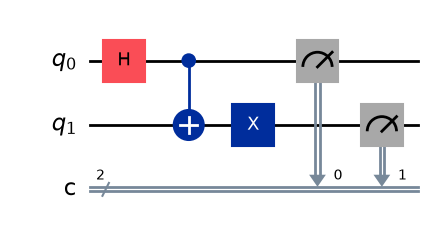

In [3]:
qc_mod = QuantumCircuit(2, 2)
qc_mod.h(0)
qc_mod.cx(0, 1)
qc_mod.x(1)            # the single added gate
qc_mod.measure([0, 1], [0, 1])
display(qc_mod.draw(output='mpl'))

## 3. Run both circuits (100 shots each) and compare

Original Bell circuit : {'00': 52, '11': 48} -> same-bit fraction = 100%
Modified (with X on q1): {'01': 45, '10': 55} -> same-bit fraction = 0%


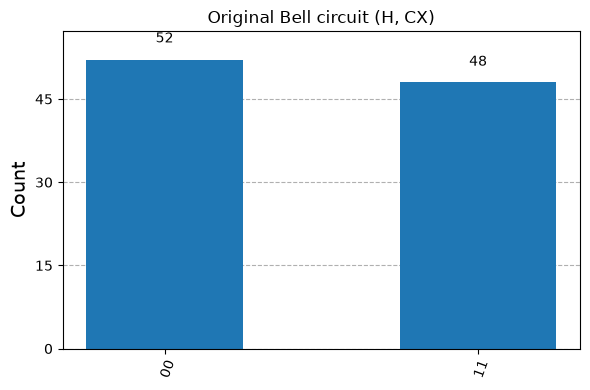

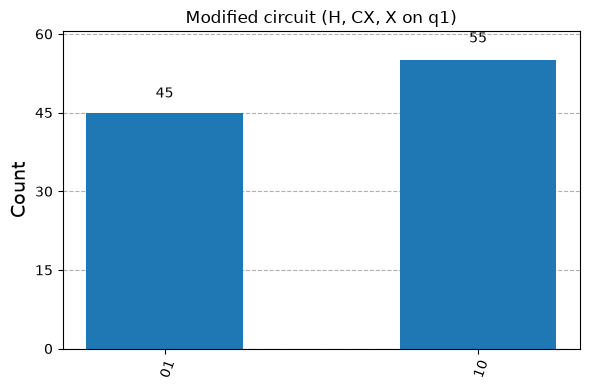

In [4]:
counts_bell = run(qc_bell)
counts_mod  = run(qc_mod)

print("Original Bell circuit :", dict(sorted(counts_bell.items())),
      f"-> same-bit fraction = {correlated_fraction(counts_bell):.0%}")
print("Modified (with X on q1):", dict(sorted(counts_mod.items())),
      f"-> same-bit fraction = {correlated_fraction(counts_mod):.0%}")

display(plot_histogram(counts_bell, title="Original Bell circuit (H, CX)", figsize=(6,4)))
display(plot_histogram(counts_mod,  title="Modified circuit (H, CX, X on q1)", figsize=(6,4)))

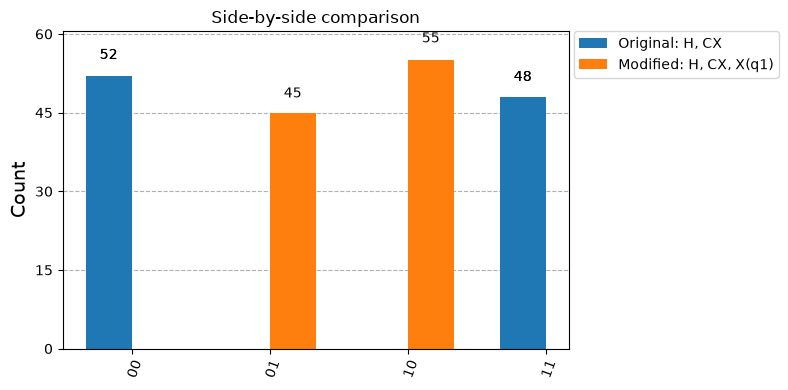

In [5]:
plot_histogram([counts_bell, counts_mod],
               legend=['Original: H, CX', 'Modified: H, CX, X(q1)'],
               title="Side-by-side comparison", figsize=(8,4))

## 4. Optional extra: other single-gate changes

Not every gate changes the *counts*. Here are two more one-gate variants for comparison:

| Variant | State | Expected counts |
|---|---|---|
| `Z` after CX | (|00⟩ − |11⟩)/√2 | still `00`/`11` (only the phase changed, which measurement in the Z basis cannot see) |
| `H` on q0 after CX | (|00⟩+|01⟩+|10⟩−|11⟩)/2 | all four outcomes ≈ 25 % (correlation destroyed) |

Z variant: {'00': 54, '11': 46}
H variant: {'00': 21, '01': 24, '10': 26, '11': 29}


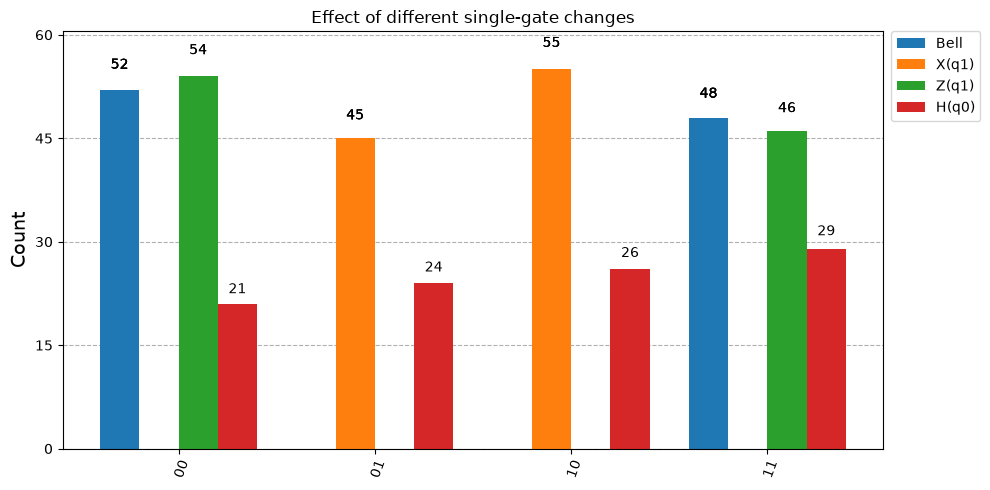

In [6]:
qc_z = QuantumCircuit(2, 2); qc_z.h(0); qc_z.cx(0, 1); qc_z.z(1); qc_z.measure([0,1],[0,1])
qc_h = QuantumCircuit(2, 2); qc_h.h(0); qc_h.cx(0, 1); qc_h.h(0); qc_h.measure([0,1],[0,1])

counts_z, counts_h = run(qc_z), run(qc_h)
print("Z variant:", dict(sorted(counts_z.items())))
print("H variant:", dict(sorted(counts_h.items())))
plot_histogram([counts_bell, counts_mod, counts_z, counts_h],
               legend=['Bell', 'X(q1)', 'Z(q1)', 'H(q0)'],
               title="Effect of different single-gate changes", figsize=(10,5))

## 5. Explanation of the observed change

In the original circuit, the Hadamard puts qubit 0 in superposition and the CNOT entangles qubit 1 with it, producing (|00⟩ + |11⟩)/√2. Measuring gives `00` or `11` with about 50 % each, so the two bits always match.

Adding an `X` gate on qubit 1 after the CNOT flips that qubit's |0⟩ and |1⟩ components, so the state becomes (|01⟩ + |10⟩)/√2. The qubits are still entangled and still perfectly correlated with each other, but the correlation is now **opposite**: the histogram moves from `00`/`11` to `01`/`10`, each near 50 %. The small deviations from exactly 50/50 come from finite sampling with only 100 shots.

The extra variants show that the *type* of gate matters: `Z` only changes a phase, so the counts stay the same; a second `H` on qubit 0 rotates the measurement basis for that qubit and spreads the probability over all four outcomes, removing the visible correlation.